# Task 3: Customer Cohort Retention & Churn Analytics (IBM Telco Dataset)

**Internship:** Datheon Data Analytics & Power BI Internship  
**Application ID:** DT-2026-KG3SS  
**Difficulty:** Intermediate  
**Tools Used:** Python (`Pandas`, `NumPy`, `Matplotlib`, `Seaborn`), Jupyter Notebook  

---

## Objective
Analyze telecom/SaaS customer retention behavior using the **IBM Telco Customer Churn** dataset. Segment customers by tenure vintage cohorts, contract types, internet service tiers, technical support adoption, and payment methods to compute retention curves, churn probabilities, and strategic retention recommendations.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 120

## 1. Data Loading & Quality Profiling
* **Dataset Size:** 7,043 customer accounts across 21 features.
* **Data Anomaly Resolution:** 11 newly onboarded accounts (`tenure = 0`) contain blank spaces (`" "`) in `TotalCharges`. These are coerced to numeric and imputed with `0.00` to preserve all customer records.

In [5]:
# Load dataset (adjust path if stored in the same folder)
df = pd.read_csv('/content/telco_customer_churn (1).csv')

# Clean TotalCharges and map binary Churn target
blank_charges = (df['TotalCharges'].astype(str).str.strip() == '').sum()
print(f"Blank TotalCharges records imputed with 0: {blank_charges}")

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
df['Churn_Flag'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Baseline Churn Benchmark
total_customers = len(df)
churned_customers = df['Churn_Flag'].sum()
baseline_churn = (churned_customers / total_customers) * 100

print(f"Total Customers: {total_customers:,}")
print(f"Churned Customers: {churned_customers:,}")
print(f"Baseline Churn Rate: {baseline_churn:.2f}%")

Blank TotalCharges records imputed with 0: 11
Total Customers: 7,043
Churned Customers: 1,869
Baseline Churn Rate: 26.54%


## 2. Tenure Cohort & Contract Retention Matrix

--- Retention Rate (%) by Tenure Cohort & Contract Type ---
Contract       Month-to-month  One year  Two year
Tenure_Cohort                                    
0–12 Mos                48.65     89.52    100.00
13–24 Mos               62.28     91.88    100.00
25–48 Mos               67.08     89.38     97.81
49–60 Mos               72.22     86.29     96.03
61+ Mos                 77.78     87.86     96.86


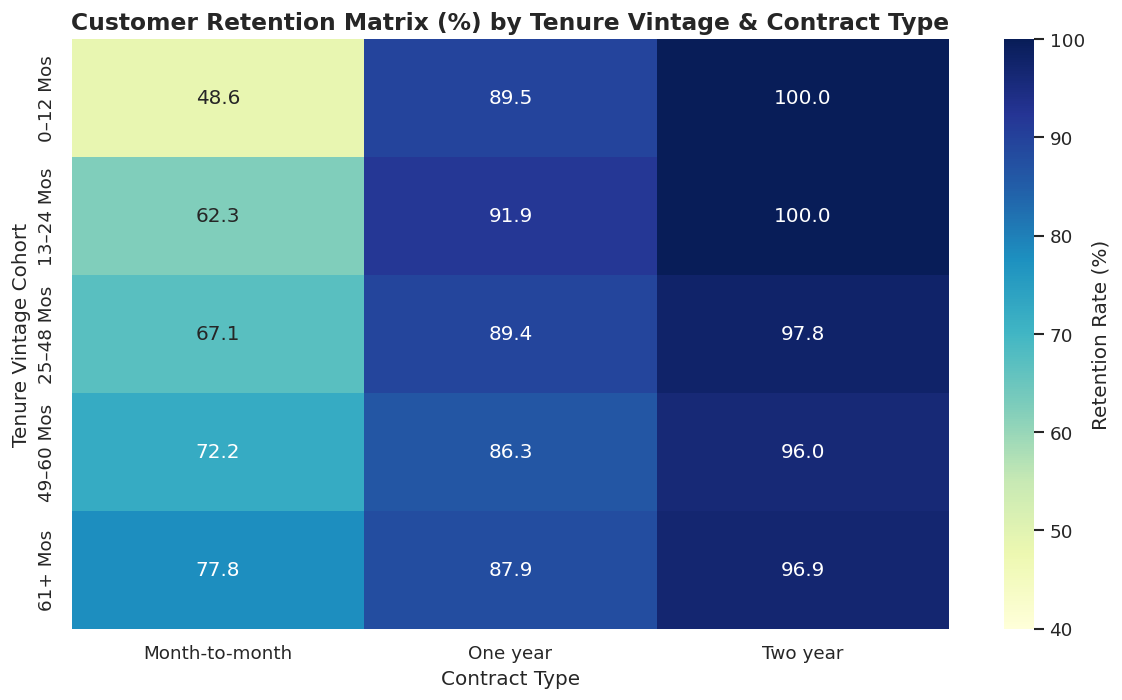

In [6]:
# Group customers into Tenure Vintage Cohorts
bins = [-1, 12, 24, 48, 60, 100]
labels = ['0–12 Mos', '13–24 Mos', '25–48 Mos', '49–60 Mos', '61+ Mos']
df['Tenure_Cohort'] = pd.cut(df['tenure'], bins=bins, labels=labels)

# Compute Churn & Retention Rates by Tenure Cohort and Contract Type
churn_matrix = df.pivot_table(
    index='Tenure_Cohort',
    columns='Contract',
    values='Churn_Flag',
    aggfunc='mean',
    observed=False
) * 100

retention_matrix = 100 - churn_matrix
print("--- Retention Rate (%) by Tenure Cohort & Contract Type ---")
print(retention_matrix.round(2))

# Plot Cohort Retention Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    retention_matrix,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    cbar_kws={'label': 'Retention Rate (%)'},
    vmin=40,
    vmax=100
)
plt.title('Customer Retention Matrix (%) by Tenure Vintage & Contract Type', fontsize=14, fontweight='bold')
plt.xlabel('Contract Type')
plt.ylabel('Tenure Vintage Cohort')
plt.tight_layout()
plt.savefig('cohort_retention_heatmap.png', dpi=300)
plt.show()

## 3. High-Risk Service Tier & Payment Method Segmentation

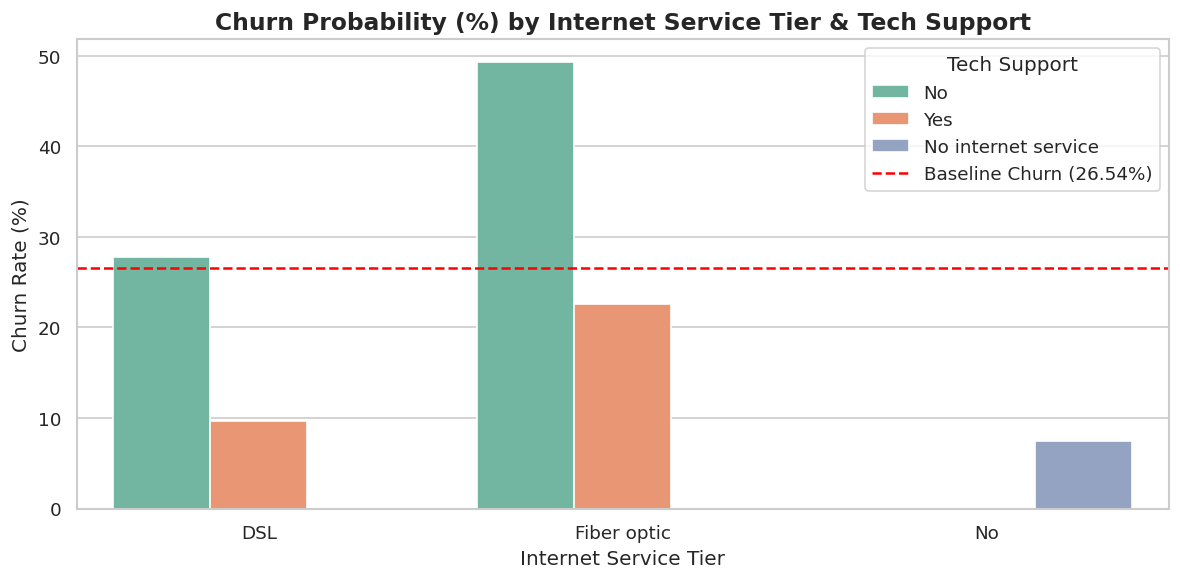


--- Churn Performance by Payment Method ---
                           Customers  Churned  Churn_Rate_Pct  \
PaymentMethod                                                   
Electronic check                2365     1071           45.29   
Mailed check                    1612      308           19.11   
Bank transfer (automatic)       1544      258           16.71   
Credit card (automatic)         1522      232           15.24   

                           Avg_Monthly_Charges  
PaymentMethod                                   
Electronic check                         76.26  
Mailed check                             43.92  
Bank transfer (automatic)                67.19  
Credit card (automatic)                  66.51  


In [7]:
# Visualization 2: Churn Probability by Internet Service Tier & Tech Support
plt.figure(figsize=(10, 5))
sns.barplot(
    data=df,
    x='InternetService',
    y=df['Churn_Flag'] * 100,
    hue='TechSupport',
    palette='Set2',
    errorbar=None
)
plt.axhline(baseline_churn, color='red', linestyle='--', linewidth=1.5, label=f'Baseline Churn ({baseline_churn:.2f}%)')
plt.title('Churn Probability (%) by Internet Service Tier & Tech Support', fontsize=14, fontweight='bold')
plt.ylabel('Churn Rate (%)')
plt.xlabel('Internet Service Tier')
plt.legend(title='Tech Support')
plt.tight_layout()
plt.savefig('high_risk_service_churn.png', dpi=300)
plt.show()

# Payment Method Churn Summary
payment_summary = df.groupby('PaymentMethod').agg(
    Customers=('customerID', 'count'),
    Churned=('Churn_Flag', 'sum'),
    Churn_Rate_Pct=('Churn_Flag', lambda x: x.mean() * 100),
    Avg_Monthly_Charges=('MonthlyCharges', 'mean')
).sort_values(by='Churn_Rate_Pct', ascending=False)

print("\n--- Churn Performance by Payment Method ---")
print(payment_summary.round(2))

## 4. Executive Churn Findings & Strategic Retention Recommendations

### Key Analytical Findings
1. **Baseline Churn Benchmark:** Out of **7,043** customers, **1,869** churned (**26.54%** baseline churn rate).
2. **First-Year Month-to-Month Vulnerability:** Customers in the **0–12 Month** tenure cohort on **Month-to-Month** contracts suffer a **51.35%** churn rate, whereas **Two-Year** contracts maintain **97.17%** overall retention.
3. **Fiber Optic Support Gap:** **Fiber Optic** customers without **Tech Support** churn at **49.37%**, compared to **22.63%** for Fiber Optic users with Tech Support.
4. **Manual Payment Friction:** **Electronic Check** users churn at **45.29%**, nearly 3x higher than automatic Credit Card (**15.24%**) and Bank Transfer (**16.71%**) subscribers.

### Strategic Retention Recommendations
* **6-Month Contract Upgrade Campaign:** Target Month-to-Month subscribers at Month 6 with a 10% loyalty discount for switching to an annual contract.
* **Complimentary Fiber Optic Tech Support:** Bundle free Tech Support for the first 6 months on all new Fiber Optic plans to resolve early onboarding friction.
* **Auto-Pay Billing Incentive:** Offer a one-time $10–$15 bill credit to transition Electronic Check users onto automated card or bank billing.